In [38]:
#Get stats for plans
import pandas as pd
import matplotlib.pyplot as plt
import folium
from IPython.display import display

/Users/modekurt/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [22]:
#load documents
plans = pd.read_csv('data/Data - Master Document List.csv')
#TODO: Fix Plan Year to be int instead of string
city_list = pd.read_csv('output/capital_and_1mill_pop_cities.csv')
plans

In [57]:
#Get stats about the # of documents and years for each city
downloaded_plans = plans[plans['Document Status'] == 'Downloaded']
print(f'# of Documents: {downloaded_plans.shape[0]}')

# Number of Downloaded docs
downloaded_counts = downloaded_plans.groupby('City Code').size().reset_index()
downloaded_counts.rename(columns={0:'Downloaded Count'}, inplace=True)
print(f'# of Cities with Documents: {downloaded_counts.shape[0]}')

print(downloaded_counts)

# year range
downloaded_years = downloaded_plans.groupby('City Code')['Plan Year'].apply(list).reset_index()
downloaded_years.rename(columns={'Plan Year':'Plan Years'}, inplace=True)
print(downloaded_years)

# Merge the datasets based on common columns 'City Code'
city_doc_status = pd.merge(city_list, downloaded_counts, on='City Code', how='left')
city_doc_status = city_doc_status.merge(downloaded_years, on='City Code', how='left')
city_doc_status['Downloaded Count'] = city_doc_status['Downloaded Count'].fillna(0)

city_doc_status

# of Documents: 258
# of Cities with Documents: 113
     City Code  Downloaded Count
0        20005                 1
1        20058                 4
2        20107                 1
3        20142                 1
4        20144                 1
..         ...               ...
108     206168                 4
109     206170                 1
110     206171                11
111     206172                 1
112     206175                 4

[113 rows x 2 columns]
     City Code                                         Plan Years
0        20005                                             [2014]
1        20058                           [2010, 2020, 2015, 2018]
2        20107                                             [2009]
3        20142                                             [2015]
4        20144                                             [2016]
..         ...                                                ...
108     206168                           [2017, 2018, 2009, 2017]


,Unnamed: 0,Country,City,City Code,Latitude,Longitude,Population,ISO_Code,Language Code,Other Languages,Language,Downloaded Count,Plan Years
0,0,Afghanistan,Kabul,20002,34.528887,69.172460,4011.770,AFG,fa,"['ps', 'uz-AF', 'tk']",Persian,0.0,NaN
1,1,Algeria,El Djazaïr (Algiers),20006,36.752500,3.041970,2693.542,DZA,ar,[],Arabic,0.0,NaN
2,2,Angola,Luanda,20049,-8.836820,13.234320,7774.200,AGO,pt,[],Portuguese,0.0,NaN
3,3,Argentina,Buenos Aires,20058,-34.605083,-58.400368,14966.530,ARG,es,"['en', 'it', 'de', 'fr', 'gn']",Spanish,4.0,"[2010, 2020, 2015, 2018]"
4,4,Argentina,Córdoba,20059,-31.413500,-64.181050,1548.176,ARG,es,"['en', 'it', 'de', 'fr', 'gn']",Spanish,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
666,666,United Republic of Tanzania,Dodoma,22895,-6.172210,35.739470,261.645,TZA,sw,"['en', 'ar']",Swahili (macrolanguage),0.0,NaN
667,667,United States Virgin Islands,Charlotte Amalie,23190,18.341900,-64.930700,52.322,VIR,en,[],English,0.0,NaN
668,668,Vanuatu,Port Vila,21956,-17.733810,168.321880,52.690,VUT,bi,"['en-VU', 'fr-VU']",Bislama,0.0,NaN
669,669,Wallis and Futuna Islands,Matu-Utu,23235,-13.281630,-176.174530,1.025,WLF,wls,"['fud', 'fr-WF']",NaN,0.0,NaN


In [53]:
#First print the full city list
city_doc_status.to_csv('output/city_list_document_status.csv')

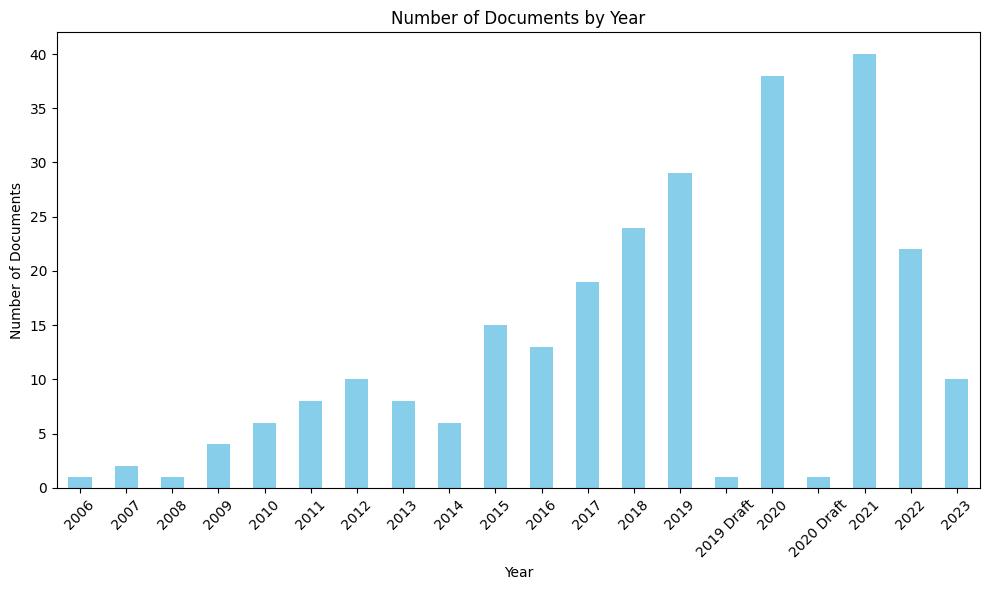

In [33]:
#Bar Char for # of Downloaded Plans
year_counts = downloaded_plans['Plan Year'].value_counts().sort_index()

# Plotting the bar chart
plt.figure(figsize=(10, 6))
year_counts.plot(kind='bar', color='skyblue')
plt.title('Number of Documents by Year')
plt.xlabel('Year')
plt.ylabel('Number of Documents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [48]:
#Map for Downloaded Plan Locations

# Create a folium map centered around the mean coordinates
map_center = [city_doc_status['Latitude'].mean(), city_doc_status['Longitude'].mean()]
my_map = folium.Map(location=map_center, zoom_start=4)

# Add markers for each data point
for index, row in city_doc_status.iterrows():
    marker_color = 'green' if row['Downloaded Count'] != 0 else 'blue'
    folium.Marker(location=[row['Latitude'], row['Longitude']], popup=row['City'], icon=folium.Icon(color=marker_color, icon='fa-solid fa-circle')).add_to(my_map)

# Display the map directly in the Jupyter Notebook
display(my_map)

my_map.save('output/downloaded_city_plans_map.html')

In [72]:
#Do something about missing plans
missing_cities = city_doc_status[city_doc_status['Downloaded Count'] == 0]
missing_cities
missing_country_counts = missing_cities.groupby('Country').size().reset_index()
print(missing_country_counts.head())
missing_country_counts.rename(columns={0:'Count'}, inplace=True)
missing_country_counts.sort_values(by=['Count'], ascending=False, inplace=True)
missing_country_counts.to_csv('output/missing_countries.csv')

#write to file to do some searches!
# missing_cities.to_csv('output/missing_cities.csv')

          Country  0
0     Afghanistan  1
1         Algeria  1
2  American Samoa  1
3         Andorra  1
4          Angola  1
